# EDA: анализ оттока клиентов телеком-компании

## Цель проекта

Исследовать факторы, связанные с оттоком клиентов, определить группы с повышенной долей оттока и сформулировать гипотезы для последующего построения модели прогнозирования.

## Бизнес-вопрос

Какие характеристики клиентов связаны с более высокой вероятностью оттока и какие клиентские сегменты требуют дополнительного исследования с точки зрения удержания?

## Этапы анализа

1. Проверка качества и структуры данных.
2. Исследование распределения целевой переменной.
3. Анализ числовых и категориальных признаков.
4. Сравнение оттока между клиентскими сегментами.
5. Проверка отдельных статистических гипотез.
6. Формулирование выводов, ограничений и следующих шагов для ML.

## Инструменты

Python, Pandas, NumPy, Matplotlib, Seaborn, SQLite.

## Описание данных

Источник: SQLite-база 'data/processed/churn.db', таблица 'customers'.

Единица наблюдения - клиент телеком-компании.

В таблице представлены сведения о стаже клиента, платежах, типе договора, подключённых услугах и других характеристиках.

Целевая переменная - 'Churn':

- 'Yes' - клиент прекратил обслуживание;
- 'No' - клиент остался.

Перед анализом проверяются структура таблицы, типы данных, пропуски, дубликаты и корректность значений.

In [1]:
import sqlite3
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

RANDOM_STATE = 42

## Загрузка данных

In [2]:
DB_PATH = Path("../data/processed/churn.db")
FIGURES_DIR = Path("../reports/figures")

if not DB_PATH.exists():
    raise FileNotFoundError(
        f"База данных не найдена: {DB_PATH.resolve()}. "
        "Проверь рабочую директорию и путь к файлу."
    )

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

with sqlite3.connect(DB_PATH) as conn:
    df = pd.read_sql_query(
        "SELECT * FROM customers",
        conn
    )

print(f"Количество строк: {df.shape[0]}")
print(f"Количество столбцов: {df.shape[1]}")
display(df.head())

Количество строк: 7032
Количество столбцов: 21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,"1,889.50",No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,"1,840.75",No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

missing = df.isna().sum()
print("Столбцы с пропусками:")
display(missing[missing > 0])

print("Полных дубликатов:", df.duplicated().sum())
print(
    "Повторяющихся customerID:",
    df["customerID"].duplicated().sum()
)

display(df.describe().T)

for col in df.select_dtypes(include="object").columns:
    print(f"\n{col}: {df[col].nunique()} уникальных значений")
    display(df[col].value_counts(dropna=False).head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 


Series([], dtype: int64)

Полных дубликатов: 0
Повторяющихся customerID: 0


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,"7,032.00",0.16,0.37,0.00,0.00,0.00,0.00,1.00
tenure,"7,032.00",32.42,24.55,1.00,9.00,29.00,55.00,72.00
MonthlyCharges,"7,032.00",64.80,30.09,18.25,35.59,70.35,89.86,118.75
TotalCharges,"7,032.00","2,283.30","2,266.77",18.80,401.45,"1,397.47","3,794.74","8,684.80"



customerID: 7032 уникальных значений


...

PaperlessBilling
Yes    4168
No     2864
Name: count, dtype: int64


PaymentMethod: 4 уникальных значений


PaymentMethod
Electronic check             2365
Mailed check                 1604
Bank transfer (automatic)    1542
Credit card (automatic)      1521
Name: count, dtype: int64


Churn: 2 уникальных значений


Churn
No     5163
Yes    1869
Name: count, dtype: int64

## Результаты проверки качества данных

После загрузки таблица содержит 7 032 записи о клиентах и 21 столбец.

В загруженных данных пропуски не обнаружены. Типы данных соответствуют основным задачам анализа: числовые признаки представлены числовыми типами, категориальные — строковыми.

Проверены полные дубликаты строк и уникальность идентификатора `customerID`. Полных дубликатов не обнаружено, все значения customerID уникальны.
На этапе первичного анализа идентификатор `customerID` используется для идентификации клиента, но не рассматривается как содержательный признак для прогнозирования оттока.

In [4]:
churn_counts = df["Churn"].value_counts()

churn_summary = pd.DataFrame({
    "customers": churn_counts,
    "share_pct": churn_counts / len(df) * 100
})
display(churn_summary.round(2))

churn_rate = (df["Churn"] == "Yes").mean() * 100
print(f"Доля ушедших клиентов: {churn_rate:.2f}%")

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(
    data=df,
    x="Churn",
    order=["No", "Yes"],
    color="#4C72B0",
    ax=ax
)
ax.set_title("Распределение клиентов по факту оттока")
ax.set_xlabel("Отток")
ax.set_ylabel("Количество клиентов")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
fig.savefig(
    FIGURES_DIR / "churn_distribution.png",
    dpi=150,
    bbox_inches="tight"
)
plt.show()

,customers,share_pct
Churn,,
No,5163,73.42
Yes,1869,26.58


Доля ушедших клиентов: 26.58%


<Figure size 700x400 with 1 Axes>

## Интерпретация целевой переменной

В выборке 1 869 ушедших клиентов из 7 032, что составляет 26,58%. Оставшиеся клиенты составляют 73,42%.

Таким образом, классы распределены неравномерно. При дальнейшем построении модели accuracy следует оценивать вместе с метриками, учитывающими качество обнаружения ушедших клиентов.

В качестве основных метрик для сравнения моделей можно рассмотреть precision, recall, F1-score и ROC-AUC. Выбор основной метрики зависит от цели прогнозирования и допустимого соотношения ложноположительных и ложноотрицательных прогнозов.

На этапе EDA не делается вывод о том, что использование `class_weight='balanced'` обязательно улучшит модель. Это вариант, который следует проверить экспериментально.

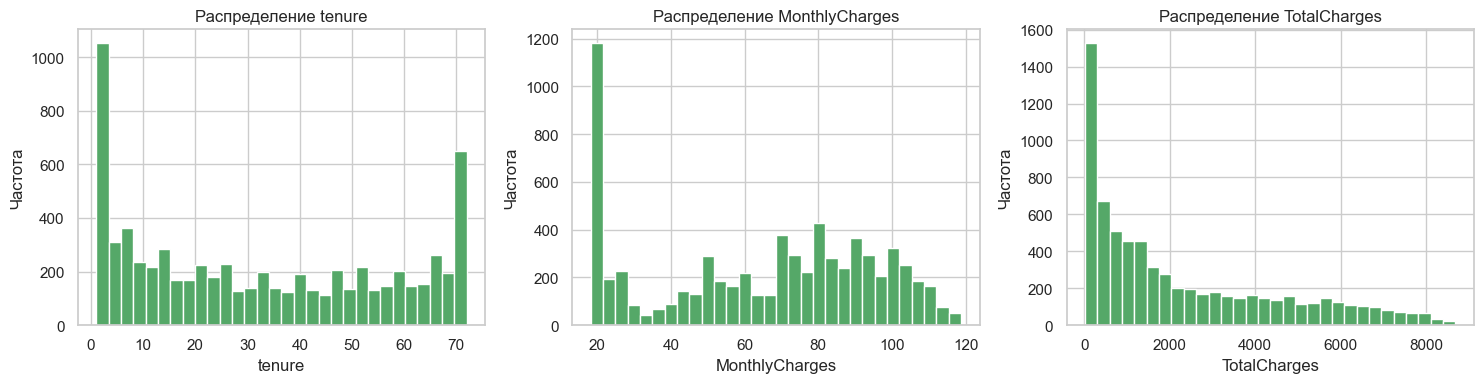

In [5]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for col, ax in zip(num_cols, axes):
    df[col].hist(ax=ax, bins=30, color='#55A868')
    ax.set_title(f'Распределение {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Частота')

plt.tight_layout()
plt.savefig('../reports/figures/numeric_distributions.png', dpi=150)
plt.show()

## Выводы:
  tenure - много новых клиентов, и много лояльных, бимодальное распределение, новый клиент - главный риск;
  MonthlyCharges - нелинейно связан с оттоком;
  TotalCharges - кумуятивная величина, сильно скошена вправо, связана с tenure;

Все три признака **не нормально распределены**, это важно для выбора модели и препроцессинга.
Нужен feature engineering: 'tenure_bucket', 'avg_monthly'.

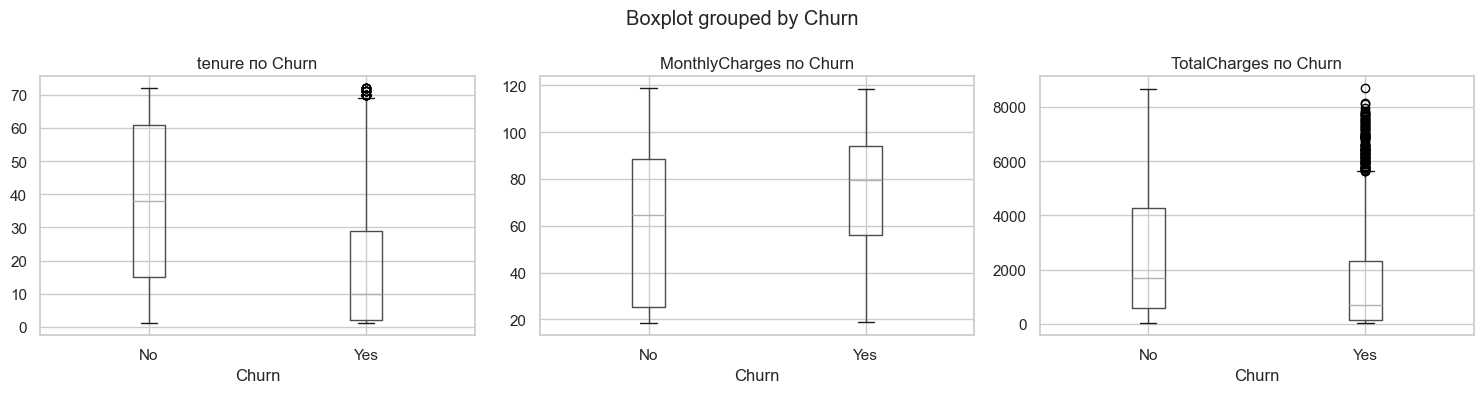

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for col, ax in zip(['tenure', 'MonthlyCharges', 'TotalCharges'], axes):
    df.boxplot(column=col, by='Churn', ax=ax)
    ax.set_title(f'{col} по Churn')
plt.tight_layout()
plt.savefig('../reports/figures/numeric_by_churn.png', dpi=150)
plt.show()

## Разница в медиане и разбросе между ушедшими и оставшимися
Общий вывод: отток концентрируется среди новых клиентов с относительно высоким ежемесячным платежом; tenure главный признак, TotalCharges во многом его дублирует, MonthlyCharges слабее. Распределения ненормальны и скошены, поэтому нужны feature engineering (tenure_bucket, avg_monthly) и осторожность с линейными моделями.

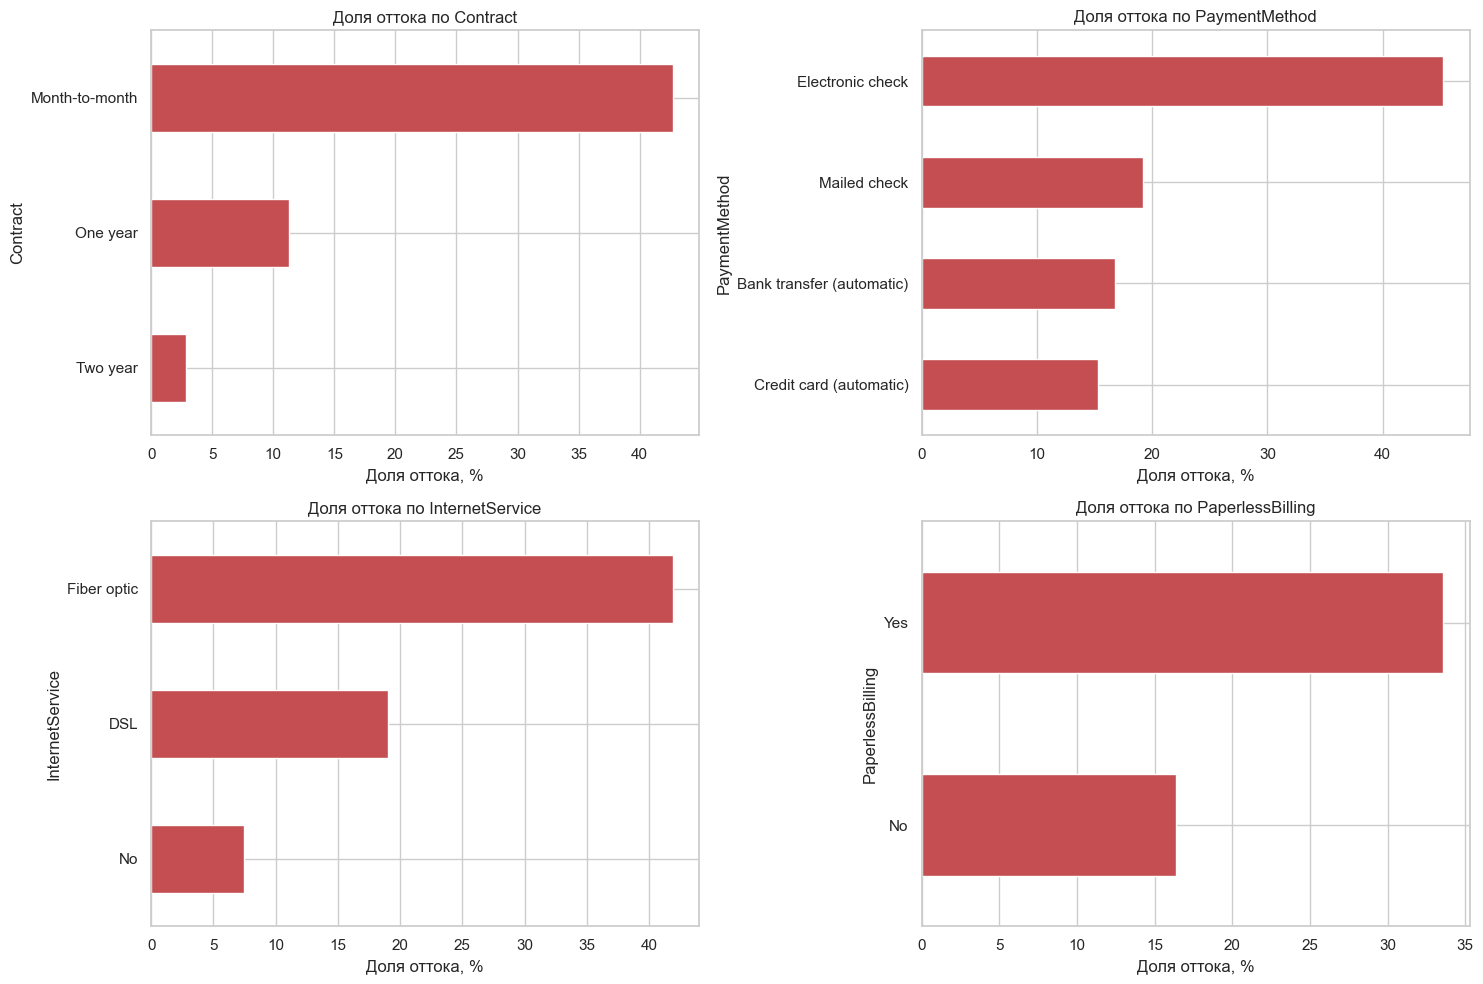

In [7]:
cat_cols = ['Contract', 'PaymentMethod', 'InternetService', 'PaperlessBilling']

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for col, ax in zip(cat_cols, axes.ravel()):
    churn_rate = df.groupby(col)['Churn'].apply(lambda x: (x == 'Yes').mean() * 100)
    churn_rate.sort_values().plot(kind='barh', ax=ax, color='#C44E52')
    ax.set_title(f'Доля оттока по {col}')
    ax.set_xlabel('Доля оттока, %')

plt.tight_layout()
plt.savefig('../reports/figures/categorical_churn.png', dpi=150)
plt.show()

## Категориальные признаки: доля оттока по категориям


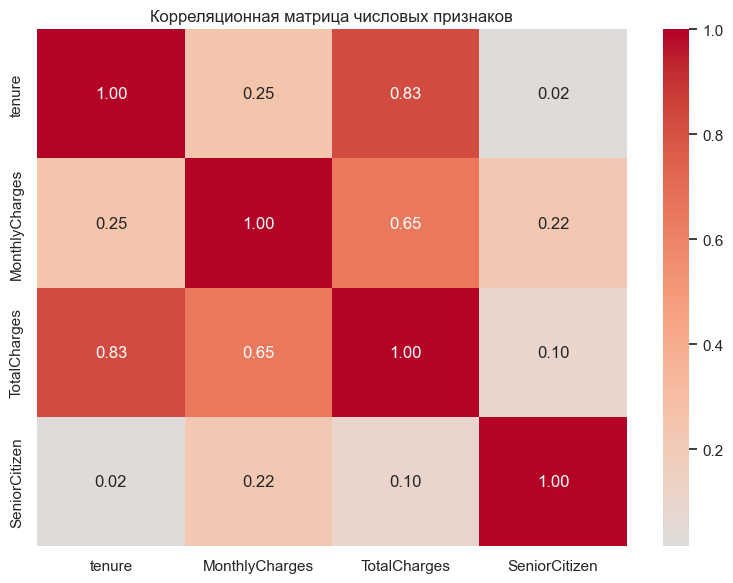

In [8]:
plt.figure(figsize=(8, 6))
corr = df[['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.savefig('../reports/figures/correlation_heatmap.png', dpi=150)
plt.show()

## Корреляции:


## Итоговые выводы EDA

### Целевая переменная
- Ушло 1869 клиентов (26.6%), осталось 5163 (73.4%).
- **Классы несбалансированы** → при обучении использовать `class_weight='balanced'` и метрики F1, ROC-AUC (не accuracy).

### Сильнейшие факторы оттока
1. **Тип контракта** — Month-to-month 42.7% оттока vs Two year 2.85%. Разница в **15 раз**.
2. **Стаж (tenure)** — медиана у ушедших в ~3 раза ниже. Новые клиенты (0–12 мес) уходят в **5 раз** чаще «стариков».
3. **Способ оплаты** — Electronic check 45.3% vs Credit card 15.3% (в **3 раза**).
4. **PaperlessBilling** — Yes 33.6% vs No 16.4% (в **2 раза**).
5. **MonthlyCharges** — ушедшие платят больше (74 vs 61 в среднем).

### Распределения числовых признаков
- `tenure` — бимодальное (пики у 0 и ~70).
- `MonthlyCharges` — бимодальное (дешёвый сегмент ~20, дорогой ~80).
- `TotalCharges` — сильно скошено вправо (кумулятивная величина).
- Все признаки **не нормальны** → масштабирование обязательно, деревья подойдут лучше линейных моделей.

### Feature engineering для ML
- `tenure_bucket` — разбить tenure на группы (0–12, 13–24, 25–48, 49+).
- `avg_monthly = TotalCharges / tenure` — средний чек за всё время.
- Возможно `is_expensive = MonthlyCharges > 70` — отделить дорогой сегмент.
- `StandardScaler` для числовых, `OneHotEncoder` для категориальных.

### Гипотезы для модели
- Contract, tenure, MonthlyCharges — топ-3 признака.
- Взаимодействие «новый клиент + месячный контракт» → максимальный риск.
- LogisticRegression должна дать F1 > 0.75.

### Ограничения
- Данные из одного датасета (Kaggle Telco), возможно, не отражают все сегменты реального рынка.
- Классы несбалансированы — метрики на тесте надо интерпретировать с осторожностью.
